In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [3]:
from dataset import CANDatasetEnet as CANDataset
import torch
from torchvision import transforms, datasets
import tqdm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report
import numpy as np
# from main_vit import get_predict
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

In [4]:
seed = 1
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [5]:
mean = (0.5, 0.5)
std = (0.5, 0.5)
normalize = transforms.Normalize(mean=mean, std=std)
transform = transforms.Compose([normalize])
transform = transforms.Compose([normalize])

In [6]:
# test_dataset = CANDataset(root_dir='../data/can-ml/can-ml/2017-subaru-forester/290626/TFRecord_w64_s32/1/', window_size=32, is_train=False, is_test=True, include_data=False, transform=transform)
test_dataset = CANDataset(root_dir='../data/can-ml/can-ml/2017-subaru-forester/010726/merged_rid2TFRecord_w128_s64/2/', window_size=32, is_train=False, is_test=True, include_data=False, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [7]:
print(test_dataset.root_dir)
print(len(test_dataset))

../data/can-ml/can-ml/2017-subaru-forester/010726/merged_rid2TFRecord_w128_s64/2/test
13118


In [8]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# def draw_confusion_matrix(cm, classes, save_file=None):
#     cm_df = pd.DataFrame(cm,
#                      index = classes, 
#                      columns = classes)
#     mask = np.zeros_like(cm)
#     np.fill_diagonal(mask, 1)
#     plt.figure(figsize=(10,8))
#     # sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, linewidths=0.5)
#     sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, 
#             linewidths=0.5, vmin=0, vmax=2500,)
#     plt.xticks(rotation=45, ha='right')
#     plt.title('Confusion Matrix')
#     plt.ylabel('Actual Values')
#     plt.xlabel('Predicted Values')
#     plt.savefig(save_file, dpi=200)
#     plt.show()

def draw_confusion_matrix(cm, classes, save_file=None):
    cm = np.array(cm, dtype=float)

    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    cm_ratio = cm / row_sums  # giữ [0,1], KHÔNG nhân 100

    cm_df = pd.DataFrame(cm_ratio, index=classes, columns=classes)
    annot_labels = cm_df.map(lambda x: f'{x:.4f}')  # "0.9980" - 4 chữ số thập phân

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_df, annot=annot_labels, fmt='', cmap='YlGnBu', cbar=False,
                linewidths=0.5, vmin=0, vmax=1)  # vmax=1 vì thang [0,1]
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.tight_layout()
    if save_file:
        plt.savefig(save_file, dpi=200)
    plt.show()
    plt.close()
   

### CCT-RetNet-SupCon with classifier

In [11]:
## CCT-RetNet model
from networks.cct_retnet import CCTRetNet
# cct_retnet_model = CCTRetNet(
#         img_size = 64,
#         embedding_dim = 128, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
#         n_conv_layers = 2, # number of convolutional layers
#         kernel_size = 3,
#         stride = 1,
#         padding = 1,
#         pooling_kernel_size = 2,
#         pooling_stride = 2,
#         pooling_padding = 0,
#         # num_layers = 4, # the number of transformer encoder layers
#         # num_heads = 4, # the number of attention heads in each transformer encoder layer
#         mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 128 * 2.5 = 320
#         num_classes = 10,
#         positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
#         projection_dim=64,
#         n_layers=2,
#         n_heads=2
#     )

cct_retnet_model = CCTRetNet(
        img_size = 32,
        embedding_dim = 128, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
        n_conv_layers = 1, # number of convolutional layers
        kernel_size = 3, # width = 8
        stride = 1, # width = 8
        padding = 1, # width = 0
        pooling_kernel_size = 3, # width = 1 
        pooling_stride = 2, # width = 1
        pooling_padding = 0,
        # num_layers = 4, # the number of transformer encoder layers
        # num_heads = 4, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 128 * 2.5 = 320
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
        projection_dim=64,
        n_layers=2,
        n_heads=2
    )


In [12]:
cct_retnet_model_path = '../save/CAN-ML_models/GPaCo+32by32-image+060726/GPaCo+32by32-image+060726_CAN-ML_CCT+RetNet+GPaCo+alpha=0.05+temp=0.07+emb=128+2convlayers_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/070626_155626/last.pth'
ckpt = torch.load(cct_retnet_model_path, weights_only=False)
state_dict = ckpt['model']
cct_retnet_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [14]:
from main_vit import get_predict


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cct_retnet_model = cct_retnet_model.cuda()
cct_retnet_model.eval()
# classifier = classifier.cuda()
# classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)

        outputs_before_proj, _ = cct_retnet_model(images)
        outputs = cct_retnet_model.fc(outputs_before_proj)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



100%|██████████| 205/205 [00:08<00:00, 22.89it/s]


In [21]:
f1 = f1_score(total_label, total_pred, average='weighted')
# precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
# recall = recall_score(total_label, total_pred, average='weighted')
conf_matrix = confusion_matrix(total_label, total_pred)
# accuracy = accuracy_score(total_label, total_pred)
# acc_percent = accuracy * 100 

print(f'Weighted F1 Score: {f1:.4f}')
# print(f'Accuracy: {accuracy:.4f}')
# print(f'Precision: {precision:.4f}')
# print(f'Recall: {recall:.4f}')

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)
print("Confusion Matrix:\n", conf_matrix)



Weighted F1 Score: 0.9950
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9957    0.9983    0.9970     10184
    Combined     0.9883    0.9985    0.9934       674
         DoS     1.0000    1.0000    1.0000       102
       Fuzzy     1.0000    0.8926    0.9433       149
        Gear     0.9764    0.9538    0.9650       130
    Interval     1.0000    1.0000    1.0000      1139
         RPM     0.9903    0.9318    0.9602       220
       Speed     0.9888    0.9707    0.9797       273
  Standstill     1.0000    1.0000    1.0000        94
  Systematic     0.9679    0.9869    0.9773       153

    accuracy                         0.9950     13118
   macro avg     0.9907    0.9733    0.9816     13118
weighted avg     0.9950    0.9950    0.9950     13118

Confusion Matrix:
 [[10167     8     0     0     3     0     2     3     0     1]
 [    1   673     0     0     0     0     0     0     0     0]
 [    0     0   102     0     0     0     0   

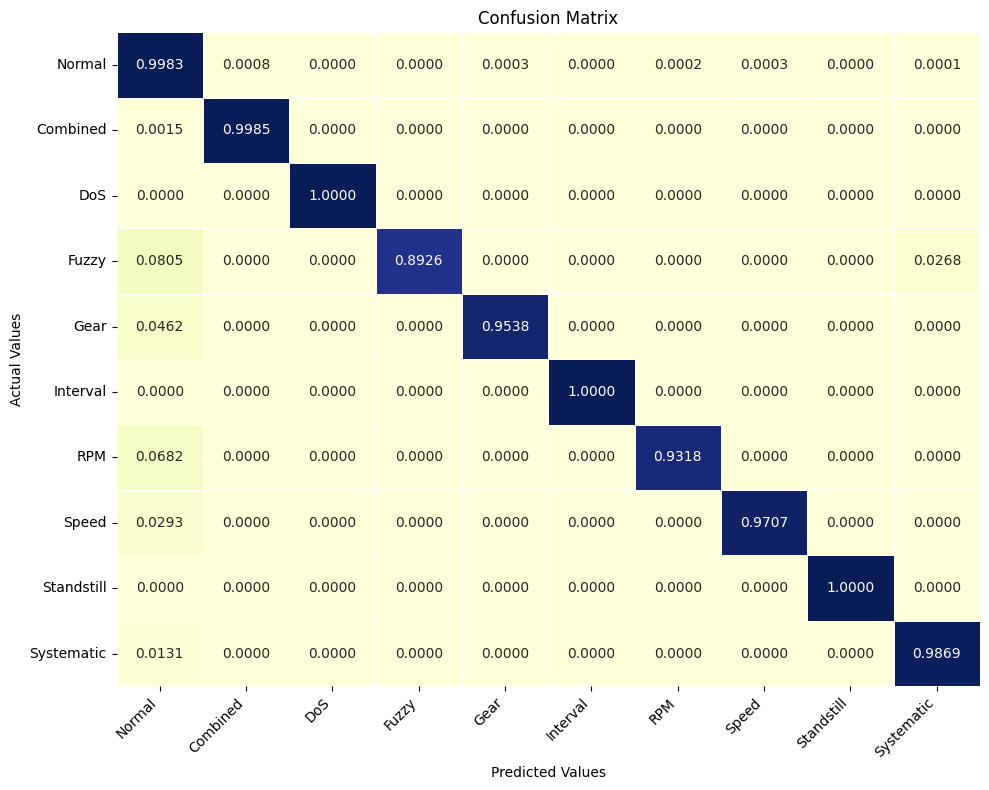

In [20]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, classes, save_file='../images/CCT-RetNet-GPaCo/alpha=5e-2/070726_32by32-image_embed=128_proj_head=mlp_aware-tokenizer_conf_matrix')

#---------------

In [26]:
def change_state_dict(state_dict):
    """
    Because state dict in distributed GPU is different
    """
    new_state_dict = {}
    for k, v in state_dict.items():
        k = k.replace("module.", "")
        new_state_dict[k] = v
    return new_state_dict

In [63]:
import torch.optim as optim
from networks.classifier import LinearClassifier
from networks.resnet_big import SupConResNet

model = SupConResNet('resnet18')
classifier = LinearClassifier(n_classes=5, feat_dim=128)

In [64]:
save_path = '../save/SupCon.resnet18.ce1_lr0.05_0.01_bs512_200epoch_temp0.07_052122_214019_cosine_warm/'
ckpt_epoch = 200
# model_path = f'{save_path}/last.pth'
model_path = f'{save_path}/models/ckpt_epoch_{ckpt_epoch}.pth'
ckpt = torch.load(model_path)
state_dict = ckpt['model']
state_dict = change_state_dict(state_dict)
model.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [65]:
class_model_path = f'{save_path}/models/ckpt_class_epoch_{ckpt_epoch}.pth'
# class_model_path = f'{save_path}/last.pth'
ckpt = torch.load(class_model_path)
state_dict = ckpt['model']
classifier.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [66]:
import numpy as np
import tqdm
total_pred = np.empty(shape=(0), dtype=int)
total_label = np.empty(shape=(0), dtype=int)
total_embs = np.empty(shape=(0, 128), dtype=float)

model = model.cuda()
classifier = classifier.cuda()
model.eval()
classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(val_loader):
        images = images.cuda(non_blocking=True)
        embs = model.encoder(images)
        outputs = classifier(embs)
        _, pred = outputs.topk(1, 1, True, True)
        pred = pred.t().cpu().numpy().squeeze(0)
        embs = embs.cpu().numpy()
        total_embs = np.concatenate((total_embs, embs), axis=0)
        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 162/162 [00:48<00:00,  3.36it/s]


In [67]:
from utils import cal_metric
cm, results = cal_metric(total_label, total_pred)
for key, values in results.items():
    print(list("{0:0.4f}".format(i) for i in values)) 

['0.0010', '0.0046', '0.0504', '0.0528', '0.0483']
['1.0000', '1.0000', '0.9995', '0.9995', '0.9995']
['0.9997', '1.0000', '1.0000', '1.0000', '1.0000']
['0.9999', '1.0000', '0.9997', '0.9997', '0.9997']


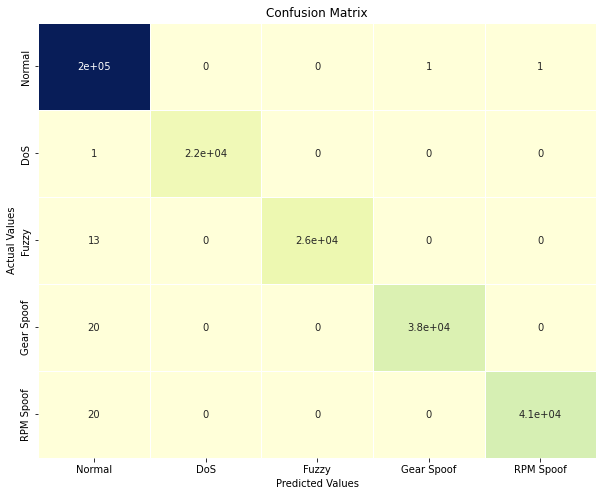

In [68]:
classes = ['Normal', 'DoS', 'Fuzzy', 'Gear Spoof', 'RPM Spoof']
draw_confusion_matrix(cm, classes, save_dir='../figures/confusion_matrix_supcon.png')